# Report the development extension
Run notebook 02 first. Charts and tables are automatically derived from saved predictions. Fold standard deviations describe variability, not confidence intervals.

In [2]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import sklearn
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'research/src/supervised/final_holdout.py').exists())
BASE=ROOT/'data/processed/supervised/v1'
ART=BASE/'assignment_artifacts_20261030T020845905141Z'
OUT=ROOT/'data/processed/supervised/development_extension_v2'
OUT.mkdir(parents=True,exist_ok=True)
features=json.loads((ART/'artifact_manifest.json').read_text())['feature_allowlist']
df=pd.read_csv(ART/'development_train.csv',dtype={'recording_id':str})
assert len(df)==184 and df.recording_id.is_unique
assert len(features)==50 and np.isfinite(df[features].to_numpy()).all()
assert not set(features)&{'model_state','location_group','recording_id','scientific_name','latitude','longitude'}
X=df[features]; y=df.model_state; groups=df.location_group
CLASSES=['AZ','CA','TX']
assert set(y)==set(CLASSES) and groups.notna().all()
print('Development only:',len(df),'recordings;',groups.nunique(),'coordinate groups')

Development only: 184 recordings; 136 coordinate groups


,mean_outer_macro_f1,fold_sd,pooled_accuracy,pooled_macro_f1
model,,,,
Random forest,0.503718,0.056235,0.521739,0.509251
Decision tree,0.491486,0.132703,0.516304,0.510205
Bernoulli NB,0.487103,0.049936,0.500000,0.490276
Multinomial NB,0.476910,0.069093,0.483696,0.476704
Logistic regression,0.451243,0.060033,0.451087,0.452085
Gaussian NB,0.369567,0.095910,0.385870,0.378607
Prior,0.170041,0.004787,0.342391,0.241311


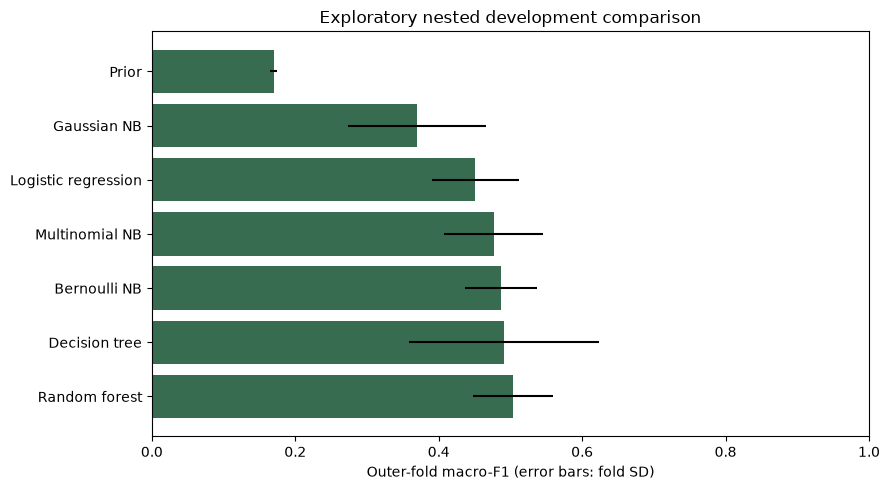

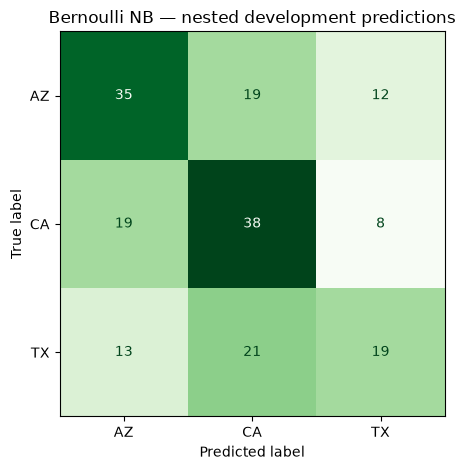

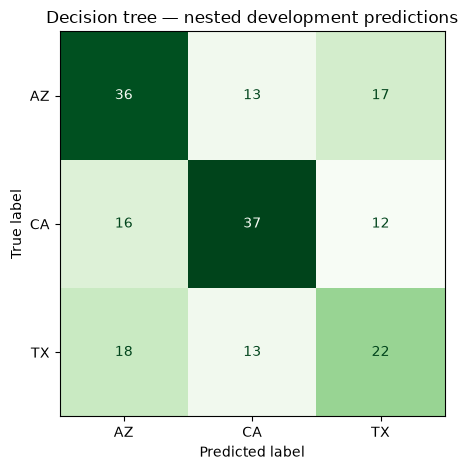

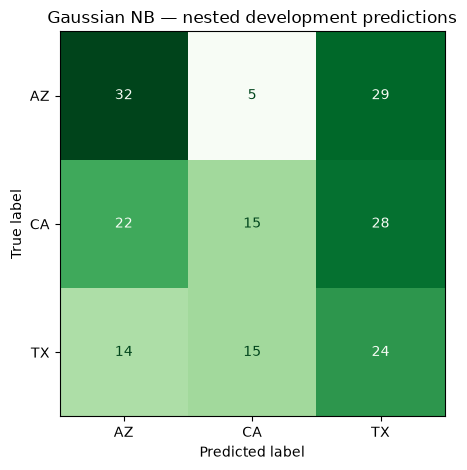

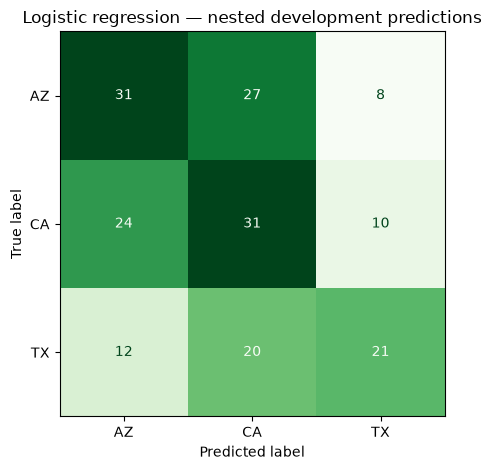

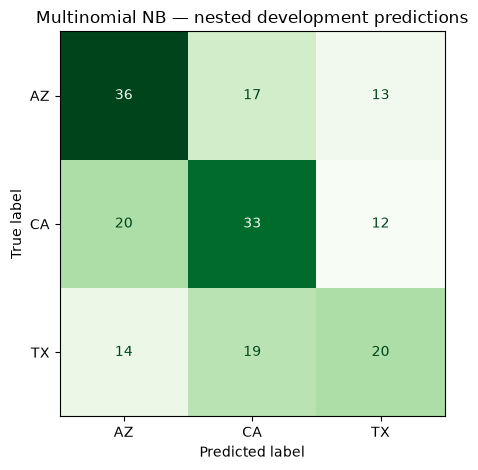

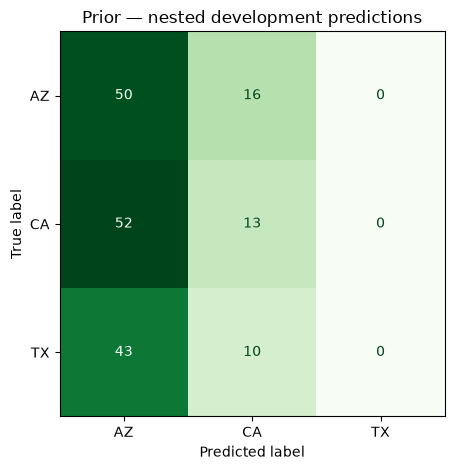

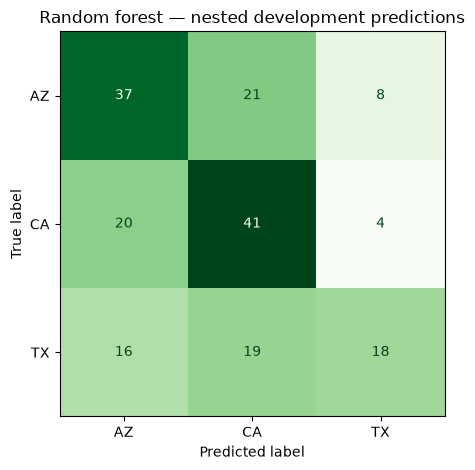

Figures, summary, and website_results_draft.txt saved to c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\development_extension_v2


In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
scores=pd.read_csv(OUT/'nested_fold_metrics.csv')
pred=pd.read_csv(OUT/'nested_oof_predictions.csv',dtype={'recording_id':str})
rows=[]
for name,part in pred.groupby('model'):
    assert len(part)==184 and part.recording_id.is_unique
    assert set(part.recording_id)==set(df.recording_id)
    rows.append({'model':name,'pooled_accuracy':accuracy_score(part.actual,part.predicted),'pooled_macro_f1':f1_score(part.actual,part.predicted,labels=CLASSES,average='macro',zero_division=0)})
summary=scores.groupby('model').macro_f1.agg(['mean','std']).rename(columns={'mean':'mean_outer_macro_f1','std':'fold_sd'}).join(pd.DataFrame(rows).set_index('model')).sort_values('mean_outer_macro_f1',ascending=False)
summary.to_csv(OUT/'development_summary.csv'); display(summary)
fig,ax=plt.subplots(figsize=(9,5)); ax.barh(summary.index,summary.mean_outer_macro_f1,xerr=summary.fold_sd,color='#376c50'); ax.set(xlabel='Outer-fold macro-F1 (error bars: fold SD)',title='Exploratory nested development comparison',xlim=(0,1)); fig.tight_layout(); fig.savefig(OUT/'development_comparison.png',dpi=180); plt.show()
for name,part in pred.groupby('model'):
    ConfusionMatrixDisplay.from_predictions(part.actual,part.predicted,labels=CLASSES,cmap='Greens',colorbar=False)
    plt.title(name+' — nested development predictions'); plt.tight_layout()
    plt.savefig(OUT/(name.replace(' ','_')+'_development_confusion.png'),dpi=160); plt.show()
report=['# New development experiments — not final-test results','',summary.to_string(),'','These analyses were designed after viewing the original test results. They cannot demonstrate an improvement on an independent test. The original selected models and final-test results remain the historical evaluation.','Any apparent leader among these families needs a prespecified training procedure and a new independent test before a generalization claim.','Exact-coordinate grouping does not ensure independence of nearby sites, species or recordists. A successful regional prediction is not a biodiversity estimate.']
(OUT/'website_results_draft.txt').write_text('\n'.join(report),encoding='utf8')
print('Figures, summary, and website_results_draft.txt saved to',OUT)